In [1]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

def compute_feature_type(pixel_value):
    if 0 <= pixel_value < 64:
        return 1
    elif 64 <= pixel_value < 128:
        return 2
    elif 128 <= pixel_value < 192:
        return 3
    elif 192 <= pixel_value < 256:
        return 4

def extract_features(image):
    features = np.zeros(4)
    for row in image:
        for pixel in row:
            feature_type = compute_feature_type(pixel)
            features[feature_type - 1] += 1
    return features / np.sum(features)

def load_images(folder_path):
    images = {}
    for filename in os.listdir(folder_path):
        if filename.endswith(".png"):
            filepath = os.path.join(folder_path, filename)
            images[filename] = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    return images

def compute_score(query_features, image_features):
    return np.prod(image_features ** query_features)

def rank_images_mle(images, query_image):
    query_features = extract_features(query_image)
    scores = {}
    for name, image in images.items():
        image_features = extract_features(image)
        scores[name] = compute_score(query_features, image_features)
    ranked_images = sorted(scores.items(), key=lambda x: x[1], reverse=True)
    return ranked_images

folder_path = 'F:/Aidin/Universities/Amirkabir (Master)/Lessons/Term 2/Pattern Recognition/Assignments/HW3/Answer/input/P4'
images = load_images(folder_path)
query_image = images.pop('test.png', None)

if query_image is None:
    raise FileNotFoundError("Query image 'test.png' not found in the folder.")

ranked_images_mle = rank_images_mle(images, query_image)
print("Ranked Images using MLE:")
for name, score in ranked_images_mle:
    print(f"{name}: {score}")

Ranked Images using MLE:
img5.png: 0.005275297041682628
img6.png: 0.0010903985097381265
img1.png: 0.0
img2.png: 0.0
img3.png: 0.0
img4.png: 0.0


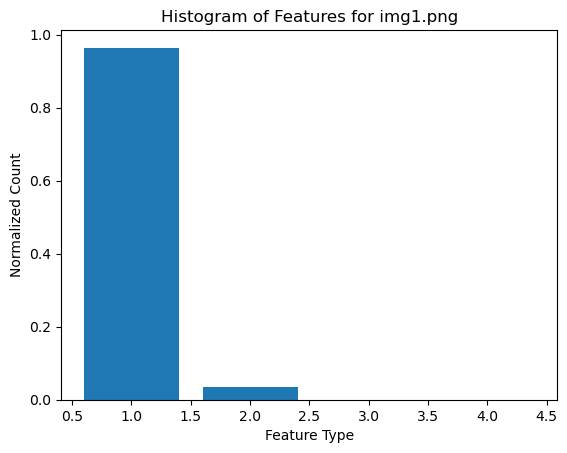

Categorical Parameters for img1.png: [0.96398926 0.03601074 0.         0.        ]


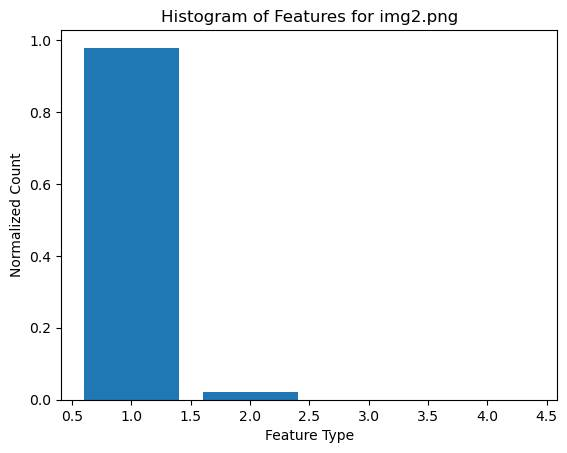

Categorical Parameters for img2.png: [0.9786377 0.0213623 0.        0.       ]


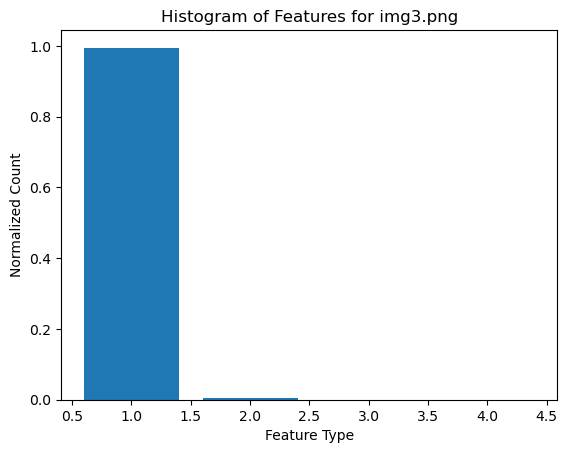

Categorical Parameters for img3.png: [9.94791667e-01 5.12695312e-03 8.13802083e-05 0.00000000e+00]


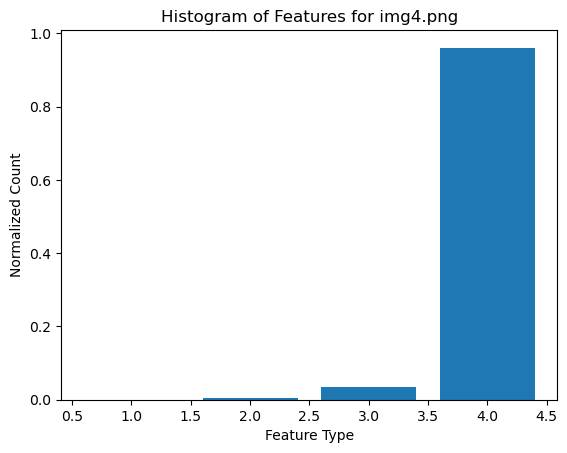

Categorical Parameters for img4.png: [0.         0.00382487 0.03515625 0.96101888]


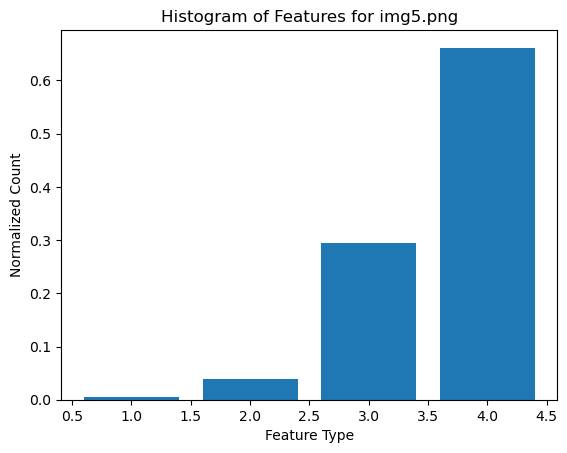

Categorical Parameters for img5.png: [0.00500488 0.03983561 0.29361979 0.66153971]


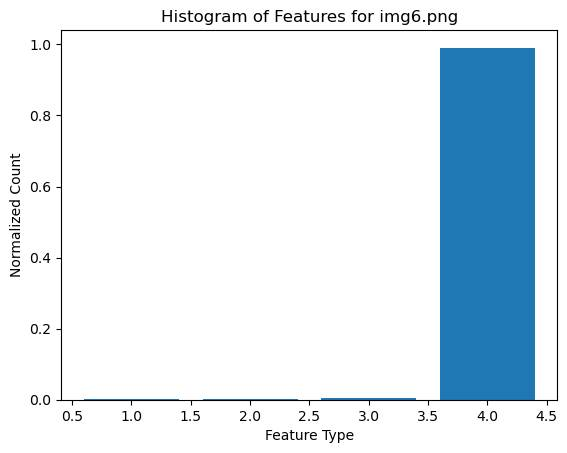

Categorical Parameters for img6.png: [0.00105794 0.00215658 0.00606283 0.99072266]


Categorical Parameters for Query Image (test.png): [0.98193359 0.01131185 0.00472005 0.00203451]


[Some figures were removed to keep the repository small; see report.pdf]


In [2]:
# Showing histograms and categorical parameters for analysis
for name, image in images.items():
    features = extract_features(image)
    plt.figure()
    plt.bar(range(1, 5), features)
    plt.xlabel('Feature Type')
    plt.ylabel('Normalized Count')
    plt.title(f'Histogram of Features for {name}')
    plt.show()
    print(f"Categorical Parameters for {name}: {features}")

# Showing histogram for query image
query_features = extract_features(query_image)
plt.figure()
plt.bar(range(1, 5), query_features)
plt.xlabel('Feature Type')
plt.ylabel('Normalized Count')
plt.title('Histogram of Features for Query Image (test.png)')
plt.show()
print(f"Categorical Parameters for Query Image (test.png): {query_features}")

In [3]:
def rank_images_map(images, query_image, eta):
    query_features = extract_features(query_image)
    population_features = np.mean([extract_features(img) for img in images.values()], axis=0)
    scores = {}
    for name, image in images.items():
        image_features = extract_features(image)
        smoothed_features = (eta * population_features + image_features) / (eta + 4)  # Updating in order to use K (4 feature types) for scaling to improve smoothing
        scores[name] = compute_score(query_features, smoothed_features)
    ranked_images = sorted(scores.items(), key=lambda x: x[1], reverse=True)
    return ranked_images

eta_values = [0, 50, 100, 500]  # Adding more eta values to observe the effect of different levels of smoothing
for eta in eta_values:
    print(f"\nRanked Images using MAP with eta={eta}:")
    ranked_images_map = rank_images_map(images, query_image, eta)
    for name, score in ranked_images_map:
        print(f"{name}: {score}")



Ranked Images using MAP with eta=0:
img5.png: 0.0013188242604206572
img6.png: 0.00027259962743453163
img1.png: 0.0
img2.png: 0.0
img3.png: 0.0
img4.png: 0.0

Ranked Images using MAP with eta=50:
img3.png: 0.45028145630382327
img2.png: 0.4500918038748975
img1.png: 0.44991803869783364
img5.png: 0.43354423125351954
img4.png: 0.4330991676219042
img6.png: 0.4330884817211535

Ranked Images using MAP with eta=100:
img3.png: 0.4586359453537842
img2.png: 0.4585368733341705
img1.png: 0.4584464790483305
img5.png: 0.4499479852311102
img4.png: 0.449713296183332
img6.png: 0.4497077133543992

Ranked Images using MAP with eta=500:
img3.png: 0.46579494783357356
img2.png: 0.4657744042849352
img1.png: 0.46575572269934884
img5.png: 0.4640026392044213
img4.png: 0.46395358644930973
img6.png: 0.463952428794704
